<a href="https://colab.research.google.com/github/atikahlestar/Data-Analysis/blob/main/Kasus_14_Market_Basket_Analysis_(Analisis_Keranjang_Belanja).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Studi Kasus 14 : Optimalisasi Strategi Penjualan Starbucks dengan Market Basket Analysis**##

Starbucks, salah satu brand kopi global ternama, memiliki banyak outlet yang tersebar di berbagai kota besar di Indonesia. Di Kota Seruni, Starbucks memiliki **10 cabang** yang melayani ratusan pelanggan setiap hari, dengan fokus pada penjualan minuman kopi
premium, makanan ringan seperti **pastry dan cake**, serta berbagai merchandise seperti tumbler dan biji kopi kemasan.

Selama beberapa bulan terakhir, manajemen Starbucks di Kota Seruni mulai menghadapi **tantangan signifikan**. Meskipun jumlah pelanggan harian masih stabil, **pendapatan rata-rata per transaksi menurun sebesar 12%**. Hal ini memicu kekhawatiran bahwa pelanggan hanya membeli satu produk utama (misalnya kopi) tanpa melakukan pembelian
tambahan.

Pihak manajemen Starbucks ingin memahami **pola belanja pelanggan** dan mencari cara untuk **meningkatkan jumlah item dalam setiap transaksi** agar pendapatan per transaksi bisa kembali meningkat.

## **Step 01 : Business Problem**##

Manajemen Starbucks Kota Seruni mengidentifikasi beberapa **permasalahan utama** yang harus segera ditangani:

1. **Penurunan Rata-Rata Pembelian Tambahan**

  - Dalam model bisnis Starbucks, keuntungan tidak hanya berasal dari
  penjualan produk utama (kopi), tetapi juga dari pembelian tambahan seperti
  makanan ringan, merchandise, atau minuman pelengkap. Jika pelanggan
  hanya membeli produk utama, potensi peningkatan nilai transaksi (Average
  Basket Value) tidak dimanfaatkan. Starbucks ingin memaksimalkan
  keuntungan per kunjungan pelanggan, sehingga setiap transaksi idealnya
  mencakup lebih dari satu item.

2. **Kurangnya Cross-Selling Efektif**

  - Strategi cross-selling bertujuan untuk meningkatkan penjualan dengan
  menawarkan produk tambahan yang relevan. Misalnya, jika pelanggan
  membeli kopi, maka mereka mungkin tertarik pada croissant atau chocolate
  cake. Kurangnya wawasan mengenai kombinasi produk yang diminati
  membuat peluang ini terlewatkan, sehingga rekomendasi produk yang
  diberikan kasir atau sistem e-commerce menjadi kurang efektif.

3. **Produk Favorit Kurang Terdeteksi**

  - Dalam industri makanan dan minuman, mengetahui preferensi pelanggan
  adalah kunci untuk meningkatkan pengalaman pelanggan dan efisiensi
  operasional. Jika Starbucks tidak mengetahui produk yang sering dibeli
  bersama, mereka tidak dapat merancang strategi promosi atau bundling yang
  tepat. Selain itu, produk yang populer mungkin dapat ditempatkan lebih
  strategis untuk menarik perhatian pelanggan.

4. **Stok Menumpuk pada Produk Tertentu**

  - Produk dengan siklus penjualan lambat meningkatkan biaya penyimpanan
  dan menurunkan efisiensi operasional. Dalam bisnis seperti Starbucks, stok
  yang tidak bergerak cepat dapat mengakibatkan kerugian karena produk
  seperti makanan memiliki masa kadaluarsa yang pendek. Menggunakan data untuk mempromosikan produk lambat dapat membantu mengurangi stok berlebih dan meningkatkan aliran pendapatan.

##**Step 02 : Analysis Objective**

1. **Mengidentifikasi kombinasi produk yang sering dibeli bersama**: Menemukan
pola pembelian pelanggan dengan Market Basket Analysis untuk merancang strategi
promosi yang relevan.
2. **Meningkatkan rata-rata nilai transaksi (Average Basket Value)**: Memastikan pelanggan membeli lebih dari satu produk dalam setiap transaksi.
3. **Mengoptimalkan strategi promosi dan bundling**: Merancang paket penawaran
berdasarkan data kombinasi produk yang populer.
4. **Mengurangi stok yang tidak produktif**: Mendorong penjualan produk lambat melalui promosi terarah.


##**Step 03 : Key Questions**

1. Kombinasi produk apa yang dapat digunakan untuk strategi bundling atau promosi?
2. Bagaimana cara meningkatkan rata-rata jumlah item per transaksi pelanggan?
3. Apa pola pembelian pelanggan terhadap makanan ringan dan minuman non-kopi?
4. Bagaimana cara mengurangi stok produk lambat tanpa menurunkan kualitas layanan
pelanggan?

##**Step 04 : Data Findings**

In [9]:
import pandas as pd
file_path = "https://drive.google.com/uc?export=download&id=1s1nNPLrqjCJ48qE0m9OEPZBr7dra7Lob"
dataset = pd.read_csv(file_path)
dataset.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({'Chocolate Cake'}),frozenset({'Cappuccino'}),0.266,0.274,0.074,0.278195,1.015312,1.0,0.001116,1.005812,0.020546,0.158798,0.005779,0.274134
1,frozenset({'Cappuccino'}),frozenset({'Chocolate Cake'}),0.274,0.266,0.074,0.270073,1.015312,1.0,0.001116,1.005580,0.020773,0.158798,0.005549,0.274134
2,frozenset({'Croissant'}),frozenset({'Cappuccino'}),0.260,0.274,0.078,0.300000,1.094891,1.0,0.006760,1.037143,0.117117,0.171053,0.035813,0.292336
3,frozenset({'Cappuccino'}),frozenset({'Croissant'}),0.274,0.260,0.078,0.284672,1.094891,1.0,0.006760,1.034490,0.119376,0.171053,0.033340,0.292336
4,frozenset({'Cappuccino'}),frozenset({'Frappuccino'}),0.274,0.242,0.078,0.284672,1.176329,1.0,0.011692,1.059653,0.206470,0.178082,0.056295,0.303493


**Market Basket Analysis Rules Update penjelasan kolom**

1. **antecedents**

  - **Deskripsi:** Item atau kelompok item awal yang menjadi "penyebab" dalam
analisis asosiasi. Biasanya ini adalah item yang telah dibeli.

  - **Cara Baca:** Contoh: frozenset({'Chocolate Cake'}) berarti
pembelian Chocolate Cake menjadi item awal dalam asosiasi.

2. **consequents**
  - **Deskripsi:** Item atau kelompok item yang muncul sebagai "akibat" atau item
yang sering dibeli bersamaan dengan antecedents.
  - **Cara Baca:** Contoh: frozenset({'Cappuccino'}) berarti Cappuccino
sering dibeli bersama Chocolate Cake.

3. **antecedent support**
  - **Deskripsi:** Proporsi transaksi yang mengandung antecedents.
  - **Cara Baca:** Nilai 0.266 berarti 26.6% dari total transaksi mengandung
Chocolate Cake.

4. **consequent support**
  - **Deskripsi:** Proporsi transaksi yang mengandung consequents.
  - **Cara Baca:** Nilai 0.274 berarti 27.4% dari total transaksi mengandung
Cappuccino.

5. **support**
  - **Deskripsi:** Proporsi transaksi yang mengandung kedua item (antecedents
dan consequents) secara bersamaan.
  - **Cara Baca:** Nilai 0.074 berarti 7.4% dari total transaksi mengandung
Chocolate Cake dan Cappuccino.

6. **confidence**
  - Deskripsi: Kemungkinan consequents muncul ketika antecedents dibeli.
  - Cara Baca: Nilai 0.278 berarti ada 27.8% peluang bahwa pembelian
Chocolate Cake diikuti oleh pembelian Cappuccino.

7. **lift**
  - **Deskripsi:** Indikator kekuatan hubungan antara antecedents dan
consequents dibandingkan dengan peluang pembelian independen.
  - **Cara Baca:** Nilai >1 menunjukkan hubungan positif; nilai <1 menunjukkan
hubungan negatif.

8. **representativity**
  - **Deskripsi:** Ukuran seberapa representatif aturan asosiasi ini terhadap data
keseluruhan.
  - **Cara Baca:** Nilai 1.0 menunjukkan aturan ini berlaku pada seluruh dataset.

9. **leverage**
  - **Deskripsi:** Perbedaan antara probabilitas transaksi yang mengandung
antecedents dan consequents secara bersamaan dan probabilitas
independennya.
  - **Cara Baca:** Nilai leverage positif menunjukkan hubungan positif antara
antecedents dan consequents.

10. **conviction**
  - **Deskripsi:** Ukuran hubungan sebab-akibat antara antecedents dan
consequents.
  - **Cara Baca:** Nilai >1 menunjukkan hubungan yang lebih kuat dibandingkan
kebetulan.

11. **zhangs_metric**
  - **Deskripsi:** Ukuran kekuatan hubungan asosiatif berdasarkan Zhang’s Metric.
  - **Cara Baca:** Semakin besar nilainya, semakin kuat asosiasinya.

12. **jaccard**
  - **Deskripsi:** Ukuran kesamaan antara antecedents dan consequents dalam
transaksi.
  - **Cara Baca:** Nilai mendekati 1 menunjukkan hubungan yang sangat kuat.

13. **certainty**
  - **Deskripsi:** Tingkat kepastian bahwa consequents terjadi setelah
antecedents.
  - **Cara Baca:** Nilai tinggi menunjukkan keandalan aturan.

14. **kulczynski**
  - **Deskripsi:** Ukuran rata-rata probabilitas bahwa consequents muncul setelah
antecedents atau sebaliknya.
  - **Cara Baca:** Nilai tinggi menunjukkan hubungan timbal balik yang kuat.

### **1. Kombinasi produk apa yang dapat digunakan untuk strategi bundling atau promosi?**

In [10]:
# Filter Kombinasi yang cocok untuk strategi bundling/promosi?

filtered_rules = dataset[
    (dataset['lift'] > 1.2) &
    (dataset['confidence'] > 0.5)
    ].sort_values(by='lift', ascending=False)

# Tampilkan hasil
print(filtered_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

                                           antecedents  \
433            frozenset({'Latte', 'Mug', 'Sandwich'})   
404  frozenset({'Chocolate Cake', 'Green Tea Latte'...   
392  frozenset({'Coffee Beans', 'Chocolate Cake', '...   
420  frozenset({'Coffee Beans', 'Green Tea Latte', ...   
435      frozenset({'Mug', 'Frappuccino', 'Sandwich'})   
418  frozenset({'Coffee Beans', 'Croissant', 'Green...   
391  frozenset({'Coffee Beans', 'Latte', 'Chocolate...   
363  frozenset({'Coffee Beans', 'Chocolate Cake', '...   
406  frozenset({'Chocolate Cake', 'Tumbler', 'Espre...   
390  frozenset({'Coffee Beans', 'Latte', 'Green Tea...   
421  frozenset({'Croissant', 'Green Tea Latte', 'Es...   

                        consequents  support  confidence      lift  
433      frozenset({'Frappuccino'})    0.010    0.625000  2.582645  
404          frozenset({'Tumbler'})    0.010    0.625000  2.561475  
392            frozenset({'Latte'})    0.014    0.583333  2.492877  
420        frozenset({'Croi

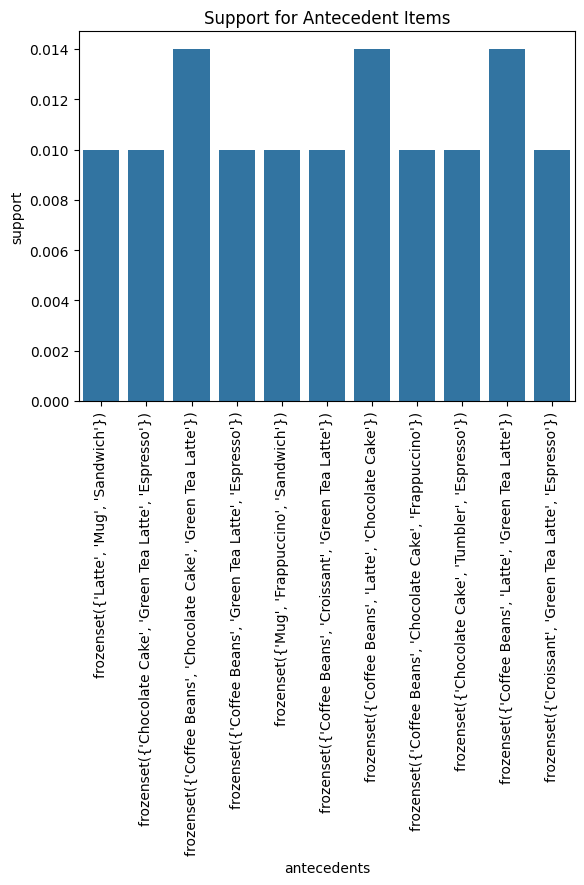

In [11]:
# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(x='antecedents', y='support', data=filtered_rules)
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability
plt.title('Support for Antecedent Items')
plt.show()

**Analisis**:
Kombinasi produk dengan confidence > 50% dan lift > 1.2 menunjukkan pola pembelian yang kuat, cocok untuk strategi bundling. Contohnya, pembelian "Latte", "Mug", dan "Sandwich" sering diikuti oleh "Frappuccino" (confidence 62.5%, lift 2.58), menandakan potensi tinggi untuk promosi paket produk terkait.

###**2. Bagaimana cara meningkatkan rata-rata jumlah item per transaksi pelanggan?**

**1. Strategi Bundling:**

- Kombinasikan produk yang memiliki lift tinggi dalam satu paket
dengan harga diskon. Misalnya, Coffee Beans, Latte, dan Chocolate
Cake dalam satu bundling dengan Green Tea Latte sebagai bonus.
- Berikan opsi bundling yang menarik, seperti "Buy 2, Get 1 Free" untuk
produk yang memiliki korelasi tinggi.

**2. Promosi Khusus:**

- Tawarkan diskon tambahan jika pelanggan membeli item tambahan
yang sering dibeli bersama (berdasarkan hasil analisis lift dan
confidence).
- Contoh: Jika pelanggan membeli Chocolate Cake, tawarkan diskon
khusus untuk membeli Cappuccino.

**3. Rekomendasi di Titik Penjualan (POS):**

- Terapkan sistem rekomendasi di kasir (fisik maupun online) yang
menyarankan produk relevan berdasarkan pola pembelian
sebelumnya.
- Misalnya, "Pelanggan yang membeli Green Tea Latte juga suka
membeli Tumbler."

**4. Tingkatkan Visualisasi Produk:**

- Tata produk-produk yang sering dibeli bersama secara berdekatan di
toko fisik.
- Di e-commerce, tampilkan kombinasi produk sebagai bagian dari
"Frequently Bought Together".

**5. Program Loyalitas:**

- Berikan poin tambahan kepada pelanggan yang membeli lebih banyak
item dalam satu transaksi.
- Misalnya, "Tambahkan 1 item lagi untuk mendapatkan poin loyalty 2x
lipat!"

**6. Upselling dan Cross-Selling:**

- Dorong staf penjualan untuk menawarkan produk tambahan
berdasarkan hasil Market Basket Analysis.
- Contoh: "Dengan membeli Coffee Beans, Anda bisa mendapatkan
diskon 20% untuk Chocolate Cake."

### **3. Apa pola pembelian pelanggan terhadap makanan ringan dan minuman non-kopi?**

Berdasarkan threshold **lift > 1.2** dan **confidence > 0.5**, berikut adalah pola
pembelian pelanggan untuk makanan ringan dan minuman non-kopi:

1. **Kombinasi Menarik:**
  - **Chocolate Cake, Tumbler, dan Green Tea Latte:** Kombinasi ini
memiliki lift tinggi (2.561475) dan confidence 0.625, menunjukkan
hubungan yang sangat kuat untuk penjualan bundling.
  - **Coffee Beans, Latte, dan Chocolate Cake → Green Tea Latte:**
Peluang tinggi untuk menawarkan Green Tea Latte bersama makanan
ringan atau kopi.

2. **Strategi Promosi:**
  - Buat paket bundling, seperti "Tea Time Combo" dengan Chocolate
Cake dan Green Tea Latte.
  - Berikan diskon tambahan untuk pembelian Latte jika pelanggan
membeli Chocolate Cake.

3. **Rekomendasi Produk:**
  - Tampilkan rekomendasi produk (frequently bought together) di
platform e-commerce atau aplikasi POS untuk meningkatkan rata-rata
nilai transaksi.


### **4. Bagaimana cara mengurangi stok produk lambat tanpa menurunkan kualitas layanan pelanggan?**

**Kriteria Prioritas untuk Produk Lambat Terjual**

1. **Support Rendah:**
  - Produk dengan support rendah (persentase transaksi yang mencakup
produk tersebut) menunjukkan frekuensi pembelian yang rendah oleh
pelanggan.

2. **Confidence Rendah dalam Asosiasi:**
  - Produk yang jarang muncul sebagai consequents dalam aturan
dengan confidence tinggi memiliki kemungkinan kecil untuk dibeli,
bahkan jika dipromosikan bersama produk lain.

3. **Lift Rendah di Semua Aturan:**
  - Produk yang tidak secara signifikan meningkatkan penjualan produk
terkait (lift mendekati atau di bawah 1) kurang bernilai jika dimasukkan
dalam bundling.

Berdasarkan analisis, produk berikut teridentifikasi sebagai produk lambat terjual
(slow-moving) karena memiliki tingkat support yang rendah, yaitu jarang muncul
dalam transaksi pelanggan:

1. Hot Chocolate
2. Tumbler
3. Croissant
4. Espresso
5. Cappuccino

**Penjelasan:**

- **Hot Chocolate** memiliki tingkat support paling rendah, artinya jarang dibeli
oleh pelanggan dibandingkan produk lainnya.
- **Tumbler dan Croissant** juga memiliki frekuensi pembelian rendah, meskipun
memiliki potensi untuk dipromosikan sebagai bagian dari bundling atau
upselling.
- **Espresso dan Cappuccino** cenderung lebih sering dikombinasikan dengan
produk lain, namun frekuensi individualnya masih rendah.


**Strategi untuk Produk Lambat:**

1. **Hot Chocolate:**
  - Promosikan sebagai tambahan gratis untuk pembelian minuman
populer seperti Latte atau Green Tea Latte.
  - Tawarkan sebagai bagian dari paket "Seasonal Treat" bersama
makanan ringan.

2. **Tumbler:**
  - Pasarkan sebagai pelengkap pembelian kopi atau minuman non-kopi
dengan diskon eksklusif.
  - Berikan sebagai hadiah dengan pembelian minimum tertentu untuk
meningkatkan daya tarik.

3. **Croissant:**
  - Gabungkan dengan minuman kopi atau teh dalam promosi "Breakfast
Combo".
  - Tempatkan di area yang lebih strategis di toko untuk meningkatkan
visibilitas.

4. **Espresso dan Cappuccino:**
  - Buat promosi "Buy 1, Get 1 Half Off" untuk meningkatkan volume
penjualan.
  - Dorong pembelian dengan menambahkan ke paket bundling bersama
makanan ringan.


##**Step 05: Business Implication**

**Strategic Implications**

- Daya Saing Perusahaan: Dengan memahami pola pembelian pelanggan, Starbucks dapat
meningkatkan efektivitas promosi dan strategi bundling, sehingga
memperkuat posisinya di pasar.
- Pengalaman Pelanggan: Analisis pola pembelian memungkinkan Starbucks menawarkan promosi yang lebih personal dan relevan, meningkatkan kepuasan pelanggan.

**Operational Implications**

- Peningkatan Efisiensi Operasional: Penempatan produk berdasarkan pola pembelian yang sering terjadi dapat
mengurangi waktu yang dihabiskan pelanggan untuk mencari produk,
meningkatkan alur belanja.
- Pengurangan Risiko Stok Berlebih: Identifikasi produk dengan siklus penjualan lambat memungkinkan
manajemen fokus pada promosi produk tersebut, sehingga menurunkan
biaya operasional.



**Financial Implications**

- Peningkatan Nilai Transaksi: Strategi bundling dan cross-selling berbasis data dapat meningkatkan
rata-rata nilai transaksi per pelanggan (Average Basket Value).
- Optimalisasi Anggaran Promosi: Promosi yang ditargetkan berdasarkan hasil MBA mengurangi pengeluaran
untuk kampanye pemasaran yang tidak efektif.

**Customer Behavior Insights**

- Identifikasi Preferensi Pelanggan: Starbucks dapat memahami kombinasi produk yang paling diminati, seperti
"Green Tea Latte dan Chocolate Cake," untuk meningkatkan rekomendasi
penjualan.
- Peluang untuk Upselling: Pelanggan yang membeli produk utama, seperti kopi, dapat diarahkan untuk
membeli produk tambahan dengan nilai tinggi, seperti merchandise.

##**Step 06 : Recommendations**

**1. Strategic Recommendations**
    
  - Promosi Bundling: Buat paket seperti "Breakfast Combo" yang menggabungkan makanan ringan dan kopi.
  - Diskon Khusus: Berikan diskon tambahan untuk pembelian produk yang sering dibeli
bersama.



**2. Operational Recommendations**

- Tata Letak Produk: Tempatkan produk yang sering dibeli bersama secara berdekatan untuk
meningkatkan pembelian impulsif.
- Otomasi Rekomendasi Produk: Gunakan sistem rekomendasi di e-commerce atau kasir untuk menawarkan produk relevan berdasarkan pembelian sebelumnya.


**3. Financial Recommendations**

- Pengurangan Stok Produk Lambat: Tawarkan diskon eksklusif untuk produk lambat seperti "Tumbler."
- Peningkatan Investasi pada Produk Populer: Fokuskan promosi pada kombinasi produk dengan lift tinggi.


**4. Customer Experience Recommendations**

- Rekomendasi Berbasis Data: Gunakan data untuk meningkatkan relevansi rekomendasi produk, seperti
"Pelanggan yang membeli Chocolate Cake juga membeli Cappuccino."
- Program Loyalitas: Tingkatkan engagement pelanggan dengan memberikan poin tambahan
untuk pembelian lebih dari satu produk.